# Credit-risk scorecard: probability of default on LendingClub loans
**Business question.** A lender receives loan applications. Which ones should it approve, and what is each applicant's probability of default (PD)?

**Data.** 42,538 LendingClub personal loans issued 2007-2011 (public loan book). The target is whether a loan was **charged off**. Only information known **at application** is used. Payment history fields (`total_pymnt`, `recoveries`, `last_pymnt_d`, ...) would leak the outcome, so they are excluded from the model and used only to measure realised profit afterwards.

**Approach.**
1. **Out-of-time validation:** train on loans issued 2007-2010 and test on 2011, as a bank would deploy a model on the next vintage.
2. **Weight-of-evidence (WoE) binning and information value (IV)** for variable selection, as used in regulatory scorecards.
3. **Logistic scorecard** converted to points (600 points at 50:1 good:bad odds, 20 points to double the odds).
4. Benchmarks: LendingClub's own **grade**, and a **gradient-boosting** model.
5. **Business cut-off:** realised portfolio profit at each approval rate.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
raw = pd.read_csv("data/lendingclub_2007_2011.csv.gz", low_memory=False)
print(raw.shape)
raw["loan_status"].value_counts()

(42538, 52)


loan_status
Fully Paid                                             33136
Charged Off                                             5634
Does not meet the credit policy. Status:Fully Paid      1988
Current                                                  961
Does not meet the credit policy. Status:Charged Off      761
Late (31-120 days)                                        24
In Grace Period                                           20
Late (16-30 days)                                          8
Default                                                    3
Name: count, dtype: int64

In [2]:
status = raw["loan_status"].str.replace("Does not meet the credit policy. Status:", "", regex=False)
df = raw[status.isin(["Fully Paid", "Charged Off"])].copy()
df["default"] = (status[df.index] == "Charged Off").astype(int)
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
df["term_m"] = df["term"].str.extract(r"(\d+)").astype(float)
df["int_rate"] = df["int_rate"].str.rstrip("%").astype(float)
df["revol_util"] = df["revol_util"].str.rstrip("%").astype(float)
df["emp_years"] = df["emp_length"].replace({"< 1 year": "0", "10+ years": "10"}).str.extract(r"(\d+)").astype(float)
df["credit_age_yrs"] = (df["issue_d"] - pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")).dt.days / 365.25
df["installment_to_income"] = df["installment"] * 12 / df["annual_inc"]
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]
print(f"{len(df):,} loans with a final outcome; default rate {df.default.mean():.1%}")
print(f"dropped {len(raw) - len(df):,} loans still current or late at the snapshot date")
df.groupby(df.issue_d.dt.year)["default"].agg(["size", "mean"]).rename(columns={"size": "loans", "mean": "default rate"})

41,519 loans with a final outcome; default rate 15.4%
dropped 1,019 loans still current or late at the snapshot date


,loans,default rate
issue_d,,
2007,603,0.262
2008,2393,0.207
2009,5281,0.137
2010,12534,0.140
2011,20708,0.158


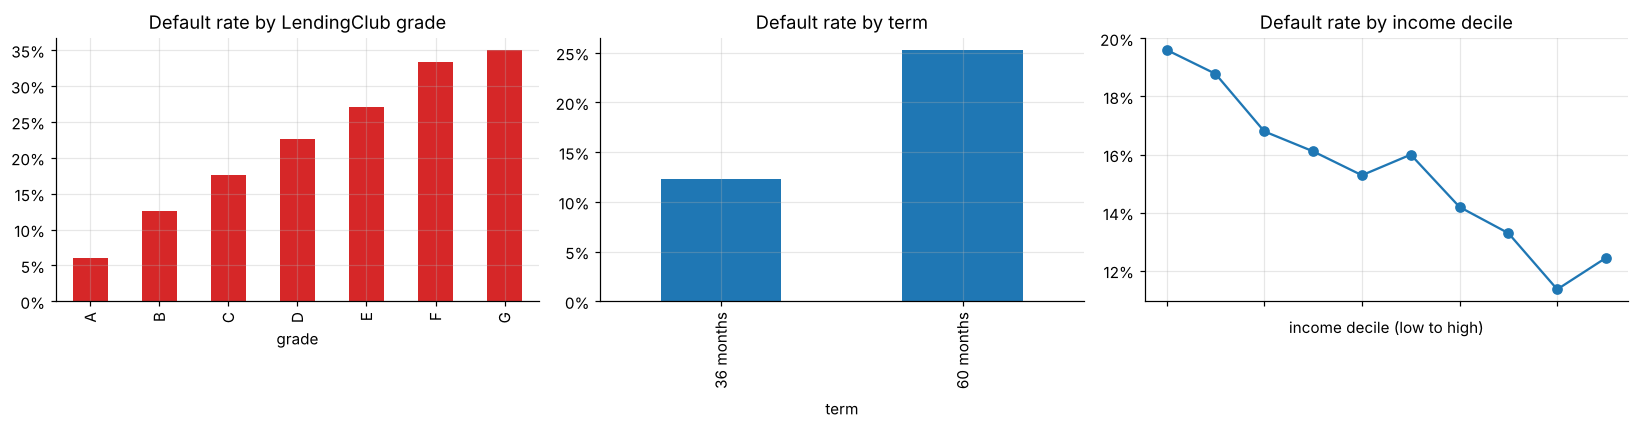

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("grade")["default"].mean().plot.bar(ax=axes[0], color="C3", title="Default rate by LendingClub grade")
df.groupby("term")["default"].mean().plot.bar(ax=axes[1], title="Default rate by term")
df.groupby(pd.qcut(df["annual_inc"], 10))["default"].mean().plot(ax=axes[2], marker="o", title="Default rate by income decile")
axes[2].set_xticklabels([]); axes[2].set_xlabel("income decile (low to high)")
for ax in axes: ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(IMG / "default_rates.png", bbox_inches="tight"); plt.show()

## Weight of evidence and information value
Each variable is cut into up to 10 bins on the **training** vintages only. For bin $i$:

$$WoE_i=\ln\frac{\%\,\text{goods}_i}{\%\,\text{bads}_i},\qquad IV=\sum_i(\%\,\text{goods}_i-\%\,\text{bads}_i)\,WoE_i$$

Rule of thumb: IV < 0.02 is useless, 0.02-0.1 weak, 0.1-0.3 medium, and above 0.3 strong (often a sign of leakage).

In [4]:
train = df[df.issue_d < "2011-01-01"].copy(); test = df[df.issue_d >= "2011-01-01"].copy()
print(f"train 2007-2010: {len(train):,} loans, default {train.default.mean():.1%} | test 2011: {len(test):,} loans, default {test.default.mean():.1%}")
num = ["loan_amnt", "term_m", "annual_inc", "dti", "delinq_2yrs", "inq_last_6mths", "open_acc", "pub_rec", "revol_bal",
       "revol_util", "total_acc", "emp_years", "credit_age_yrs", "installment_to_income", "loan_to_income", "pub_rec_bankruptcies"]
cat = ["home_ownership", "verification_status", "purpose", "addr_state"]

def woe_fit(x, y, bins=10, min_share=0.02):
    """Return a mapping function x -> WoE, plus the IV table (fitted on training data only)."""
    if not pd.api.types.is_numeric_dtype(x):
        key = x.fillna("missing")
        counts = key.value_counts(normalize=True)
        rare = counts[counts < min_share].index
        key = key.where(~key.isin(rare), "other")
        edges = None
    else:
        vals = np.unique(x.dropna())
        if len(vals) <= bins:   # few distinct values (e.g. term 36/60): one bin per value
            edges = np.r_[-np.inf, (vals[:-1] + vals[1:]) / 2, np.inf]
        else:
            q = np.unique(np.nanquantile(x, np.linspace(0, 1, bins + 1)))
            edges = np.r_[-np.inf, q[1:-1], np.inf]
        key = pd.cut(x, edges).astype(str).where(x.notna(), "missing")
        rare = []
    t = pd.crosstab(key, y)
    t.columns = ["good", "bad"]
    g, b = (t.good + 0.5) / t.good.sum(), (t.bad + 0.5) / t.bad.sum()
    t["woe"] = np.log(g / b); t["iv"] = (g - b) * t["woe"]; t["bad_rate"] = t.bad / (t.good + t.bad)
    def transform(xn):
        if edges is None:
            k = xn.fillna("missing"); k = k.where(k.isin(t.index), "other")
        else:
            k = pd.cut(xn, edges).astype(str).where(xn.notna(), "missing")
        return k.map(t["woe"]).fillna(0.0).astype(float)
    return transform, t

maps, tables = {}, {}
for c in num + cat:
    maps[c], tables[c] = woe_fit(train[c], train["default"])
iv = pd.Series({c: tables[c]["iv"].sum() for c in maps}).sort_values(ascending=False)
iv.to_frame("IV").assign(strength=pd.cut(iv, [0, .02, .1, .3, 9], labels=["useless", "weak", "medium", "strong"]))

train 2007-2010: 20,811 loans, default 15.0% | test 2011: 20,708 loans, default 15.8%


,IV,strength
inq_last_6mths,1.431e-01,medium
purpose,7.344e-02,weak
revol_util,7.027e-02,weak
pub_rec_bankruptcies,5.702e-02,weak
term_m,5.574e-02,weak
loan_to_income,3.811e-02,weak
pub_rec,3.381e-02,weak
annual_inc,3.239e-02,weak
installment_to_income,3.048e-02,weak
addr_state,2.934e-02,weak


In [5]:
t = tables["revol_util"].copy()
t["lower"] = [float(i.split(",")[0].strip("(")) if i != "missing" else np.inf for i in t.index]
t.sort_values("lower")[["good", "bad", "bad_rate", "woe"]]

,good,bad,bad_rate,woe
revol_util,,,,
"(-inf, 7.6]",1821,270,0.129,1.764e-01
"(7.6, 18.5]",1879,189,0.091,5.637e-01
"(18.5, 28.9]",1838,234,0.113,3.285e-01
"(28.9, 38.56]",1784,277,0.134,1.304e-01
"(38.56, 47.8]",1782,315,0.150,9.078e-04
"(47.8, 56.94]",1733,316,0.154,-3.013e-02
"(56.94, 66.7]",1717,364,0.175,-1.806e-01
"(66.7, 77.0]",1734,333,0.161,-8.187e-02
"(77.0, 87.91]",1688,383,0.185,-2.484e-01


In [6]:
selected = [c for c in iv.index if iv[c] >= 0.02]
print("selected:", selected)
Xtr = pd.DataFrame({c: maps[c](train[c]) for c in selected}); Xte = pd.DataFrame({c: maps[c](test[c]) for c in selected})
# drop near-duplicates: keep the higher-IV member of any pair with |corr| > 0.7
corr = Xtr.corr().abs(); drop = set()
for i, a in enumerate(selected):
    for b in selected[i + 1:]:
        if corr.loc[a, b] > 0.7 and a not in drop and b not in drop:
            drop.add(b)
final = [c for c in selected if c not in drop]
print("dropped as collinear:", sorted(drop))
lr = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr[final], train["default"])
coef = pd.Series(lr.coef_[0], index=final)
print("all WoE coefficients negative (higher WoE = safer):", bool((coef < 0).all()))
coef.sort_values()

selected: ['inq_last_6mths', 'purpose', 'revol_util', 'pub_rec_bankruptcies', 'term_m', 'loan_to_income', 'pub_rec', 'annual_inc', 'installment_to_income', 'addr_state']


dropped as collinear: ['installment_to_income']
all WoE coefficients negative (higher WoE = safer): True


revol_util             -1.068
addr_state             -1.060
term_m                 -1.055
inq_last_6mths         -1.015
purpose                -0.989
annual_inc             -0.939
loan_to_income         -0.735
pub_rec_bankruptcies   -0.613
pub_rec                -0.405
dtype: float64

## From logistic regression to scorecard points
With a base of 600 points at good:bad odds of 50:1 and 20 points to double the odds (PDO):

$$\text{factor}=\frac{20}{\ln 2},\quad \text{offset}=600-\text{factor}\ln 50,\quad \text{points}_{j,\text{bin}}=-\Big(\beta_j\,WoE_{j,\text{bin}}+\frac{\beta_0}{k}\Big)\text{factor}+\frac{\text{offset}}{k}$$

where $k$ is the number of variables. Each applicant's score is the sum of the points of their bins, so every decision can be explained line by line.

In [7]:
factor = 20 / np.log(2); offset = 600 - factor * np.log(50); k = len(final); b0 = lr.intercept_[0]
card = []
for c in final:
    t = tables[c]
    for bin_, w in t["woe"].items():
        card.append({"variable": c, "bin": bin_, "woe": w, "points": round(-(coef[c] * w + b0 / k) * factor + offset / k)})
card = pd.DataFrame(card)
card.to_csv("scorecard.csv", index=False)
def score(X): return sum(-(coef[c] * X[c] + b0 / k) * factor + offset / k for c in final)
test["score"] = score(Xte); train["score"] = score(Xtr)
card[card.variable.isin(["term_m", "inq_last_6mths", "purpose"])].round(2)

,variable,bin,woe,points
0,inq_last_6mths,"(-inf, 1.0]",0.23,66
1,inq_last_6mths,"(1.0, 2.0]",0.02,60
2,inq_last_6mths,"(2.0, 4.0]",-0.44,47
3,inq_last_6mths,"(4.0, inf]",-1.00,30
4,inq_last_6mths,missing,0.29,68
5,purpose,car,0.35,70
6,purpose,credit_card,0.38,71
7,purpose,debt_consolidation,0.01,60
8,purpose,educational,-0.40,48
9,purpose,home_improvement,0.02,60


In [8]:
grade_map = train.groupby("grade")["default"].mean()
p_grade = test["grade"].map(grade_map)
p_card = lr.predict_proba(Xte[final])[:, 1]
feat = num + cat
gb_tr, gb_te = train[feat].copy(), test[feat].copy()
for c in cat:
    cats = pd.Categorical(gb_tr[c]).categories
    gb_tr[c] = pd.Categorical(gb_tr[c], categories=cats); gb_te[c] = pd.Categorical(gb_te[c], categories=cats)
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0,
                                    categorical_features="from_dtype", random_state=0).fit(gb_tr, train["default"])
p_gb = gb.predict_proba(gb_te)[:, 1]
# does our scorecard add information beyond LendingClub's own grade? combine the two
mg, tg = woe_fit(train["sub_grade"], train["default"])
Xtr2, Xte2 = Xtr[final].assign(sub_grade=mg(train["sub_grade"])), Xte[final].assign(sub_grade=mg(test["sub_grade"]))
p_comb = LogisticRegression(max_iter=2000).fit(Xtr2, train["default"]).predict_proba(Xte2)[:, 1]

def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p); return np.max(tpr - fpr)
y = test["default"].values
res = pd.DataFrame({name: {"AUC": roc_auc_score(y, p), "Gini": 2 * roc_auc_score(y, p) - 1, "KS": ks(y, p), "Brier": brier_score_loss(y, p)}
                    for name, p in {"LendingClub grade only": p_grade, "WoE logistic scorecard (application data only)": p_card,
                                    "Scorecard + LC sub-grade": p_comb, "Gradient boosting (application data only)": p_gb}.items()}).T
res

,AUC,Gini,KS,Brier
LendingClub grade only,0.670,0.339,0.265,0.127
WoE logistic scorecard (application data only),0.695,0.391,0.294,0.124
Scorecard + LC sub-grade,0.699,0.397,0.299,0.124
Gradient boosting (application data only),0.696,0.391,0.297,0.125


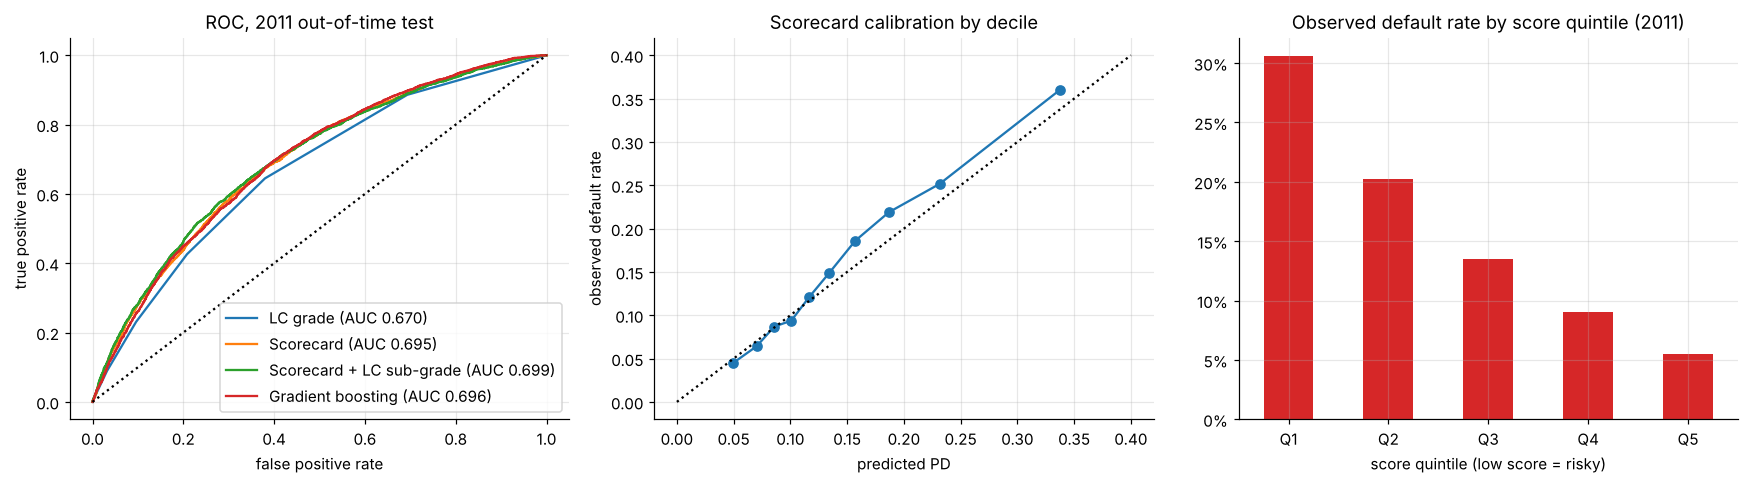

score quintile edges: [526, 538, 548, 558, 599]


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, p in {"LC grade": p_grade, "Scorecard": p_card, "Scorecard + LC sub-grade": p_comb, "Gradient boosting": p_gb}.items():
    fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set_title("ROC, 2011 out-of-time test"); axes[0].legend(); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
dec = pd.qcut(p_card, 10, labels=False)
cal = pd.DataFrame({"pred": p_card, "obs": y, "dec": dec}).groupby("dec").mean()
axes[1].plot(cal.pred, cal.obs, "o-"); axes[1].plot([0, .4], [0, .4], "k:")
axes[1].set_title("Scorecard calibration by decile"); axes[1].set_xlabel("predicted PD"); axes[1].set_ylabel("observed default rate")
bands = pd.qcut(test["score"], 5)
test.groupby(bands)["default"].mean().plot.bar(ax=axes[2], color="C3", title="Observed default rate by score quintile (2011)")
axes[2].set_xticklabels([f"Q{i}" for i in range(1, 6)], rotation=0); axes[2].set_xlabel("score quintile (low score = risky)")
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(IMG / "model_performance.png", bbox_inches="tight"); plt.show()
print("score quintile edges:", [round(i.right) for i in bands.cat.categories])

## Stability: is the 2011 population like the training population?
The **population stability index** (PSI) compares the score distributions of the two periods: below 0.1 is stable, 0.1-0.25 needs monitoring, and above 0.25 is a significant shift.

In [10]:
edges = np.quantile(train["score"], np.linspace(0, 1, 11)); edges[0], edges[-1] = -np.inf, np.inf
e = np.histogram(train["score"], edges)[0] / len(train); a = np.histogram(test["score"], edges)[0] / len(test)
psi = np.sum((a - e) * np.log(a / e))
print(f"PSI train vs 2011 = {psi:.3f}")

PSI train vs 2011 = 0.004


## The business decision: where to set the cut-off
Realised profit per loan is `total_pymnt - funded_amnt`, i.e. what the lender actually collected minus what it lent. This outcome is used for evaluation only, never as a feature. Lending is not free, though: the capital is tied up while the loan amortises. A **cost of funds** is therefore charged on the average outstanding balance, approximated as half the funded amount over the loan's realised life. Loans are ranked by predicted PD and approved from the safest down.

        loans  default_rate  gross_return_%  avg_life_yrs
grade                                                    
A      5721.0         0.065           6.670         2.256
B      6257.0         0.126          10.061         2.362
C      3710.0         0.192          10.558         2.404
D      2594.0         0.246          11.053         2.387
E      1580.0         0.292          13.910         2.476
F       660.0         0.341          12.944         2.484
G       186.0         0.355          11.853         2.302


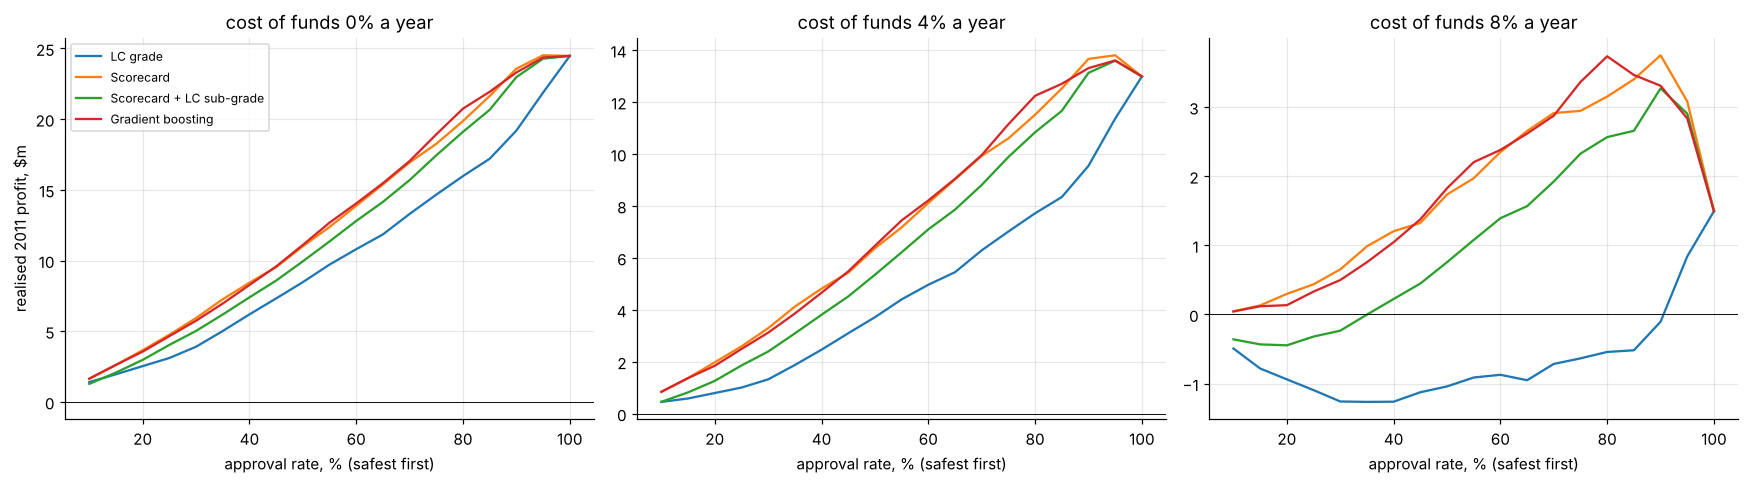

best approval rate  profit at best $m  profit approving all $m
0% LC grade                                1.00             24.470                   24.470
   Scorecard                               0.95             24.517                   24.470
   Scorecard + LC sub-grade                1.00             24.470                   24.470
   Gradient boosting                       1.00             24.470                   24.470
4% LC grade                                1.00             12.982                   12.982
   Scorecard                               0.95             13.799                   12.982
   Scorecard + LC sub-grade                0.95             13.590                   12.982
   Gradient boosting                       0.95             13.599                   12.982
8% LC grade                                1.00              1.494                    1.494
   Scorecard                               0.90              3.749                    1.494
   Scorecard + LC sub-grade                0.90              3.270                    1.494
   Gradient boosting                       0.80              3.734                    1.494

In [11]:
test["life_yrs"] = ((pd.to_datetime(test["last_pymnt_d"], format="%b-%Y") - test["issue_d"]).dt.days.clip(lower=30) / 365.25).fillna(30 / 365.25)
print(test.groupby("grade").apply(lambda g: pd.Series({"loans": len(g), "default_rate": g.default.mean(),
      "gross_return_%": 100 * (g.total_pymnt - g.funded_amnt).sum() / g.funded_amnt.sum(), "avg_life_yrs": g.life_yrs.mean()})).round(3))
def profit_curve(p, cof):
    order = np.argsort(p, kind="stable")
    prof = (test["total_pymnt"] - test["funded_amnt"] - cof * test["funded_amnt"] * test["life_yrs"] / 2).values[order]
    lent = test["funded_amnt"].values[order]
    out = []
    for share in np.arange(0.1, 1.001, 0.05):
        n = int(round(share * len(order)))
        out.append({"approval_rate": share, "profit_$m": prof[:n].sum() / 1e6, "return_%": 100 * prof[:n].sum() / lent[:n].sum()})
    return pd.DataFrame(out)
models = {"LC grade": p_grade.values, "Scorecard": p_card, "Scorecard + LC sub-grade": p_comb, "Gradient boosting": p_gb}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
summary = {}
for ax, cof in zip(axes, [0.0, 0.04, 0.08]):
    for m, p in models.items():
        c = profit_curve(p, cof); ax.plot(100 * c.approval_rate, c["profit_$m"], label=m)
        b = c.loc[c["profit_$m"].idxmax()]
        summary[(f"{cof:.0%}", m)] = {"best approval rate": b.approval_rate, "profit at best $m": b["profit_$m"],
                                      "profit approving all $m": c["profit_$m"].iloc[-1]}
    ax.axhline(0, c="k", lw=.6); ax.set_title(f"cost of funds {cof:.0%} a year"); ax.set_xlabel("approval rate, % (safest first)")
axes[0].set_ylabel("realised 2011 profit, $m"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "profit_cutoff.png", bbox_inches="tight"); plt.show()
pd.DataFrame(summary).T

## Findings
* **Out-of-time accuracy.** On the 2011 vintage, which the model never saw, the scorecard built only from application data reaches AUC 0.695 (Gini 0.39, KS 0.29). That beats LendingClub's own grade (AUC 0.670) and matches gradient boosting (0.696), while every decision stays explainable as a points table (`scorecard.csv`). Adding LendingClub's sub-grade on top adds almost nothing (0.699).
* **Strongest predictors (information value):** credit inquiries in the last 6 months (0.14), loan purpose (small-business loans are the riskiest, wedding and credit-card refinancing the safest), revolving utilisation, bankruptcies and a 60-month term (default rate 25% vs 12% for 36 months). Debt-to-income, employment length and home ownership carry almost no information once binned (IV < 0.02).
* **Discrimination translates into clear risk tiers.** The riskiest score quintile defaulted at about 31%, the safest at about 5.5%. The model is well calibrated, slightly under-predicting the riskiest decile (2011 defaults ran at 15.8% vs 15.0% in training). The score distribution is stable between periods (PSI 0.004).
* **The cut-off depends on the cost of money.** With free funding, every grade was profitable after defaults (gross returns 7-14%), so approving everyone maximises profit. At an 8% annual cost of funds, approving everyone earns only $1.5m, while declining the riskiest 10% by scorecard earns $3.7m. Ranking by LendingClub grade cannot achieve this, because its "safest" loans are also the lowest-yielding.
* **Caveats.** The 1,019 loans that were still current at the snapshot date are excluded, which slightly under-represents 2011 60-month loans. Profit uses a simple average-balance funding charge and ignores servicing costs and taxes.